# YOLO26 training and evaluation

This notebook documents the Roboflow training and evaluation. See [labeling and dataset preparation](Cv_Labeling.ipynb) for the annotation workflow. Training was performed in Roboflow; the screenshots are embedded for reference.


## Training configurations


The completed model overview identifies **YOLO26 Object Detection (Medium)**.
The live recipe shows no additional training preprocessing, separate from
version preprocessing. The following online augmentations apply to training:

| Augmentation | Settings | Probability |
| --- | --- | ---: |
| Flip | Horizontal only | 50% |
| Brightness | ±20%, darken and brighten | 100% |
| Blur | Up to 8 pixels | 3% |
| Mosaic | Expanded canvas | 100% |
| Saturation | ±50% | 100% |
| Hue | ±5° | 100% |
| Grayscale | 100% grayscale when applied | 1% |
| Affine | Scale 0.5, translation 0.1, no shear, rotation or perspective | 100% |

Roboflow lists hyperparameters as default and model input as 512 × 512.

A separate “Ready to train” screenshot shows a **YOLO26 Small** setup on
version 5, with auto-orientation listed as training preprocessing and the
following online augmentation settings:

- Horizontal flip; brightness −20% to +20%; blur up to 8 pixels.
- Mosaic with expanded canvas; saturation ±50%; hue ±5°; grayscale.
- Affine transformations: ±50% zoom and ±10% shift.

That setup warns that the version is resized to 512 × 512 while YOLO26 Small
works best at 640 × 640. The screenshot is a pre-training configuration; the Medium settings above
were verified separately in the completed model’s live training recipe.
The training graphs extend to approximately 212 epochs, but the screenshots do
not establish the precise final epoch, batch size, learning rate, or hardware.



## Evaluation and observations


The completed Medium model overview reports these **test-set** metrics:

| Metric | Result |
| --- | ---: |
| mAP@50 | 69.8% |
| mAP@50:95 | 31.4% |
| Precision | 83.0% |
| Recall | 72.6% |
| F1 | 76.9% |



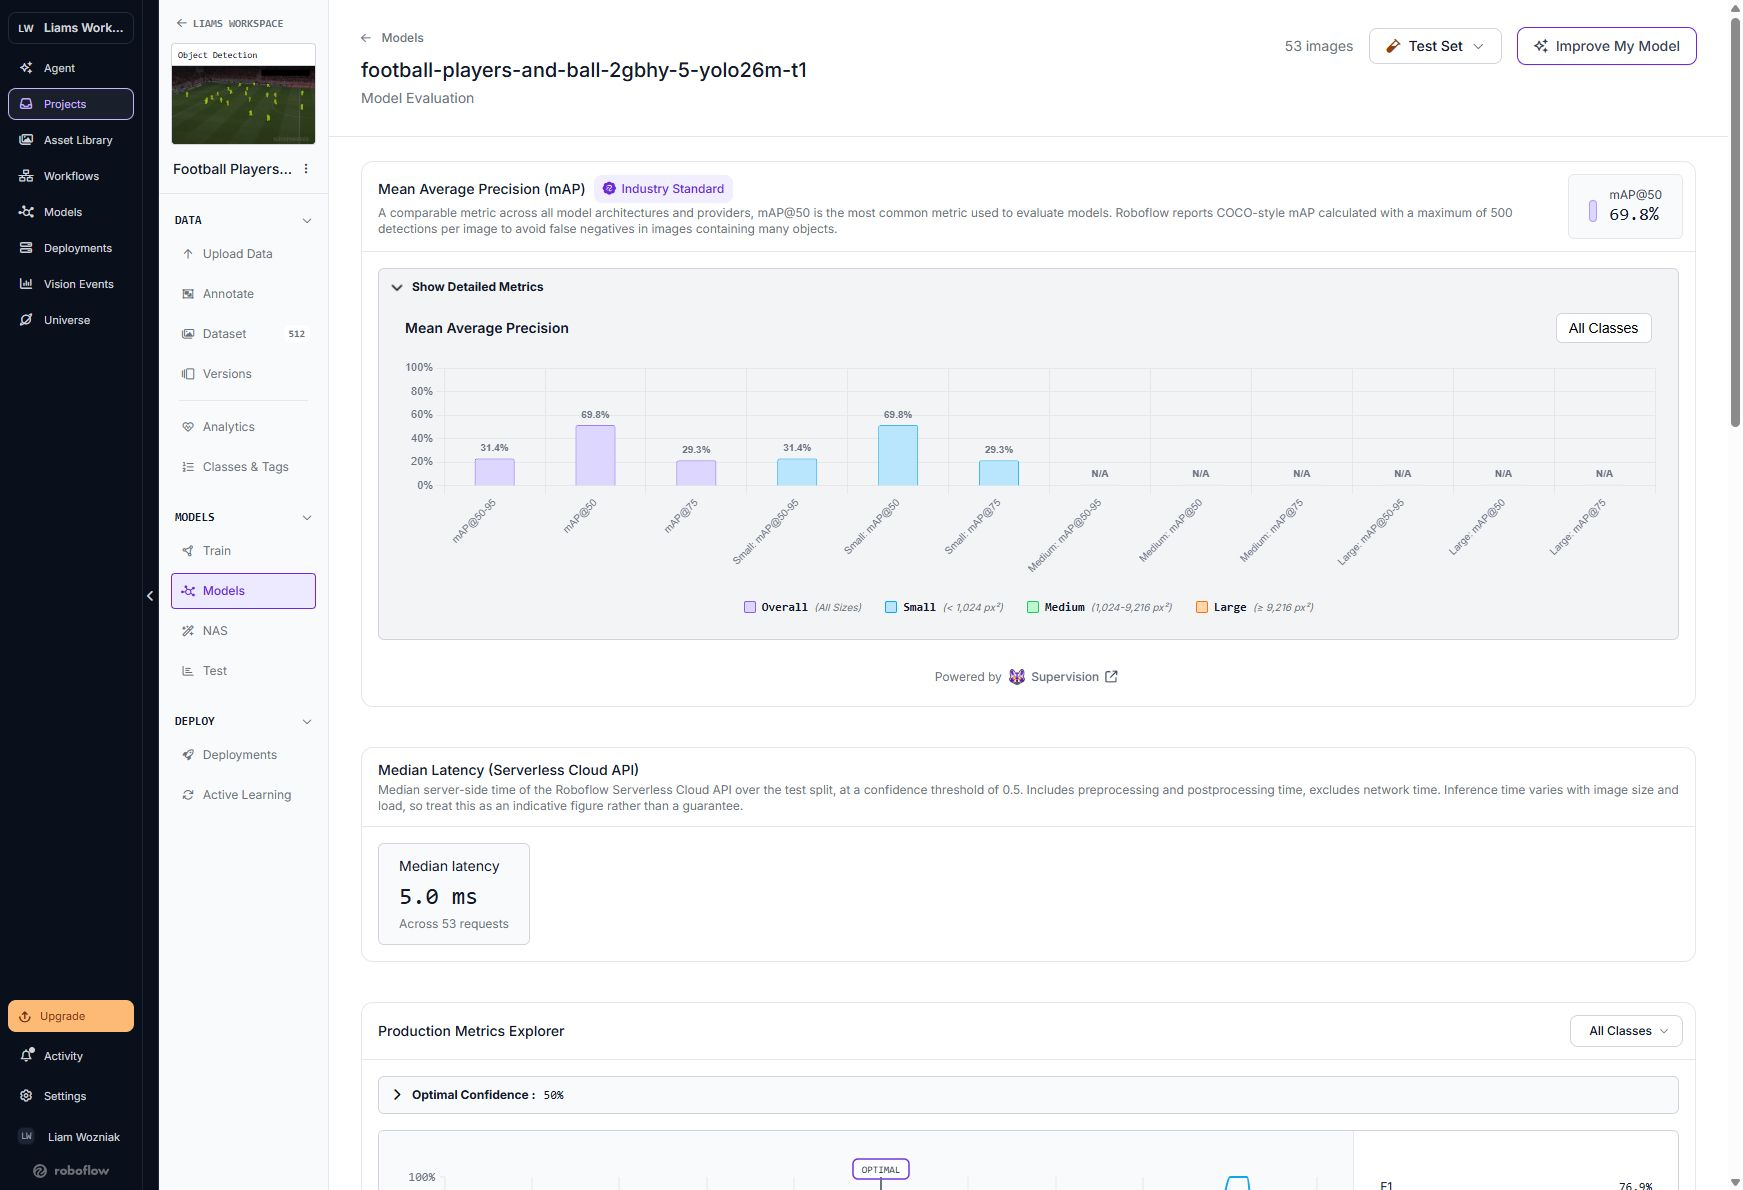

*Roboflow detailed test-set evaluation for the version 5 YOLO26 Medium model: mAP@50:95 is 31.4%.*


Roboflow's detailed industry-standard evaluation reports test-set mAP@50:95
of 31.4% across all classes and object sizes. The training graph also shows
mAP@50:95 over epochs; it is a separate training-time curve. The performance curves fluctuate while
generally rising, and the displayed box and class losses generally decrease;
the graph alone does not establish how well the model generalizes to new games.



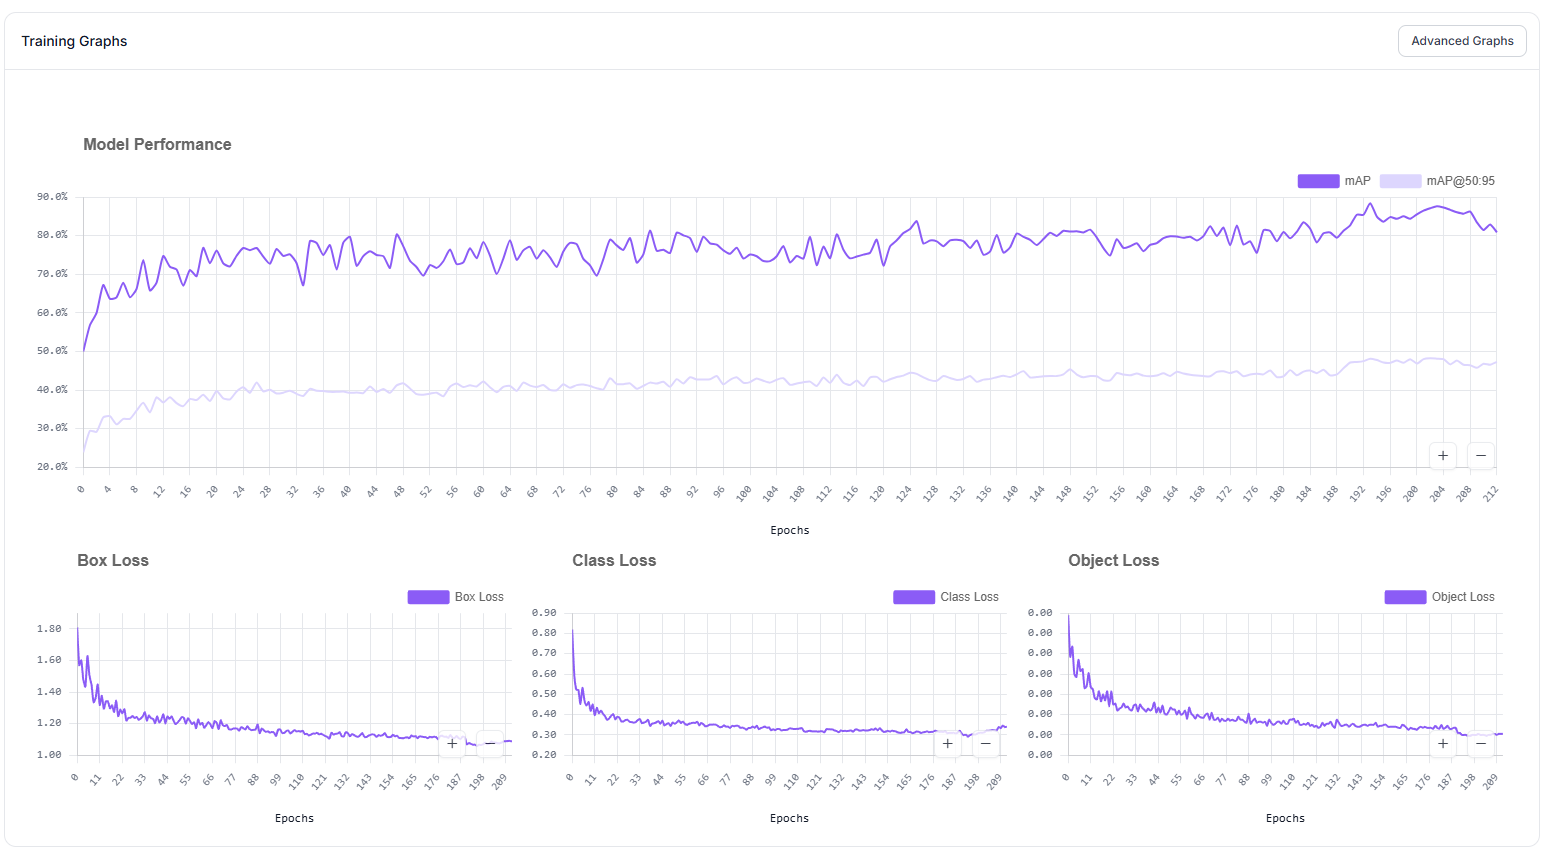

*Training performance and loss curves.*

At the confusion matrix's displayed 50% confidence threshold, approximately
1.12k player instances were correctly detected, with 35 missed player instances
and 27 false positive player detections. For `soccer ball`, 13 were correctly
detected, 14 missed, and 6 were false positives. The player count is rounded in
the screenshot. The live evaluation identifies this matrix as the test set. The matrix alone
does not establish the causes of these errors. Roboflow flags the 27 soccer ball
instances in this test evaluation as a class imbalance; this is not the count
for the whole project.

The missed balls are a useful next investigation: small size and motion blur
are plausible causes, but individual examples must be inspected before drawing
conclusions. Review false positives for officials or other people mistaken for
players, and compare misses against the annotations to distinguish model errors
from missing or inconsistent labels. The matrix alone does not establish that
linemen caused any of these specific false positives.



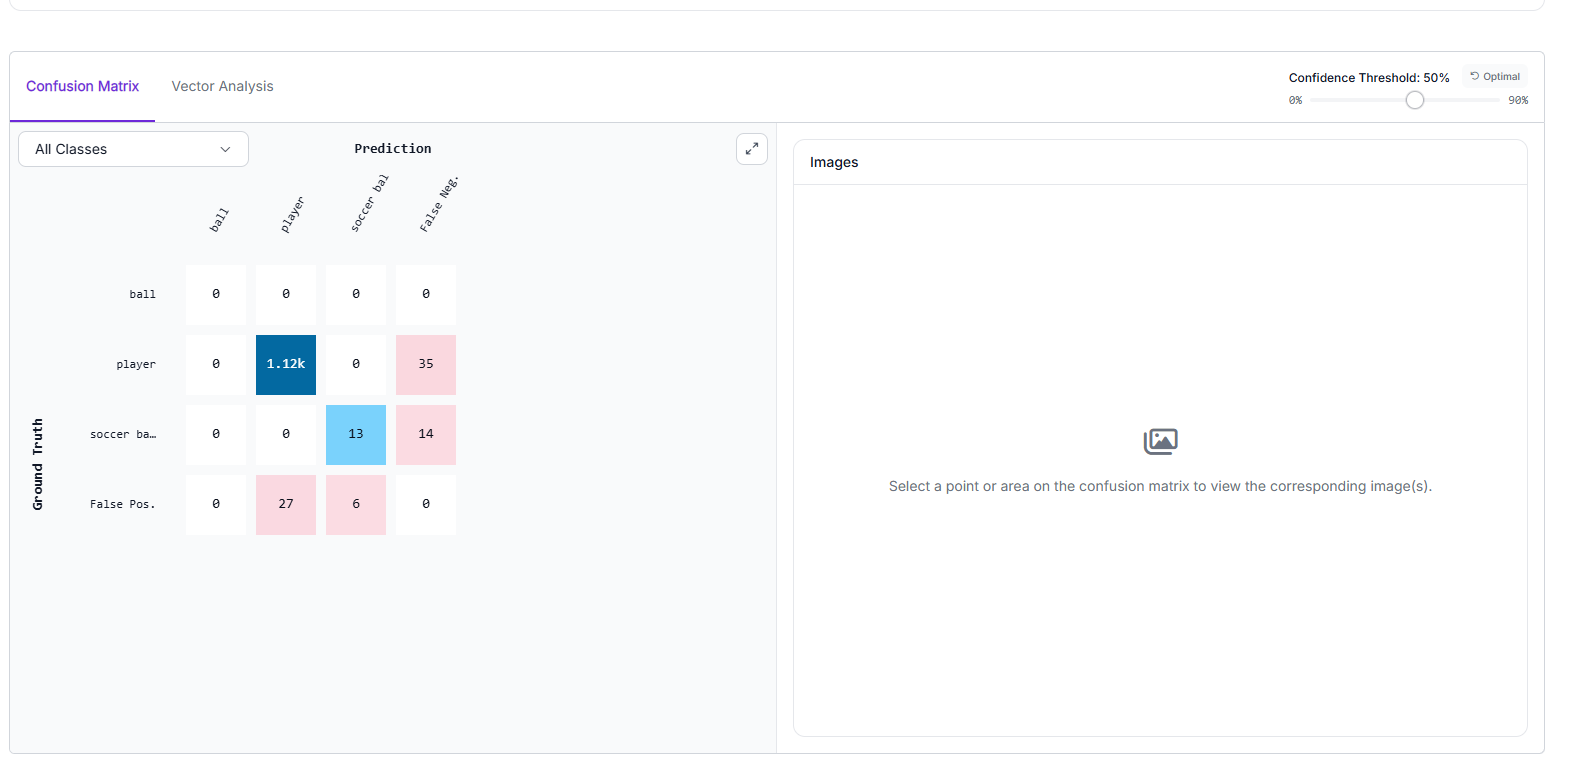

*Confusion matrix at a 50% confidence threshold.*

## Examples to inspect: missed soccer balls

These examples come from the version 5 test evaluation, at 50% confidence. Roboflow compares predictions with the stored ground truth, so a reported miss can reflect either a model error or an incorrect annotation. The images below are processed version images, not necessarily the original-resolution frames. No annotations were changed during this review.

### Frame 734

Roboflow lists 22 player boxes and **two soccer-ball ground-truth boxes**, but the prediction view lists 22 player boxes and no ball prediction at the selected threshold. The two small cyan marks lie near players; the right-hand mark is close to a player’s foot. Please inspect the original-resolution frame and surrounding video to check whether both marks really identify balls, and whether their boxes are correctly placed. If one is a shoe or another object, that label could contribute an apparent false negative; this is a hypothesis, not a confirmed error.


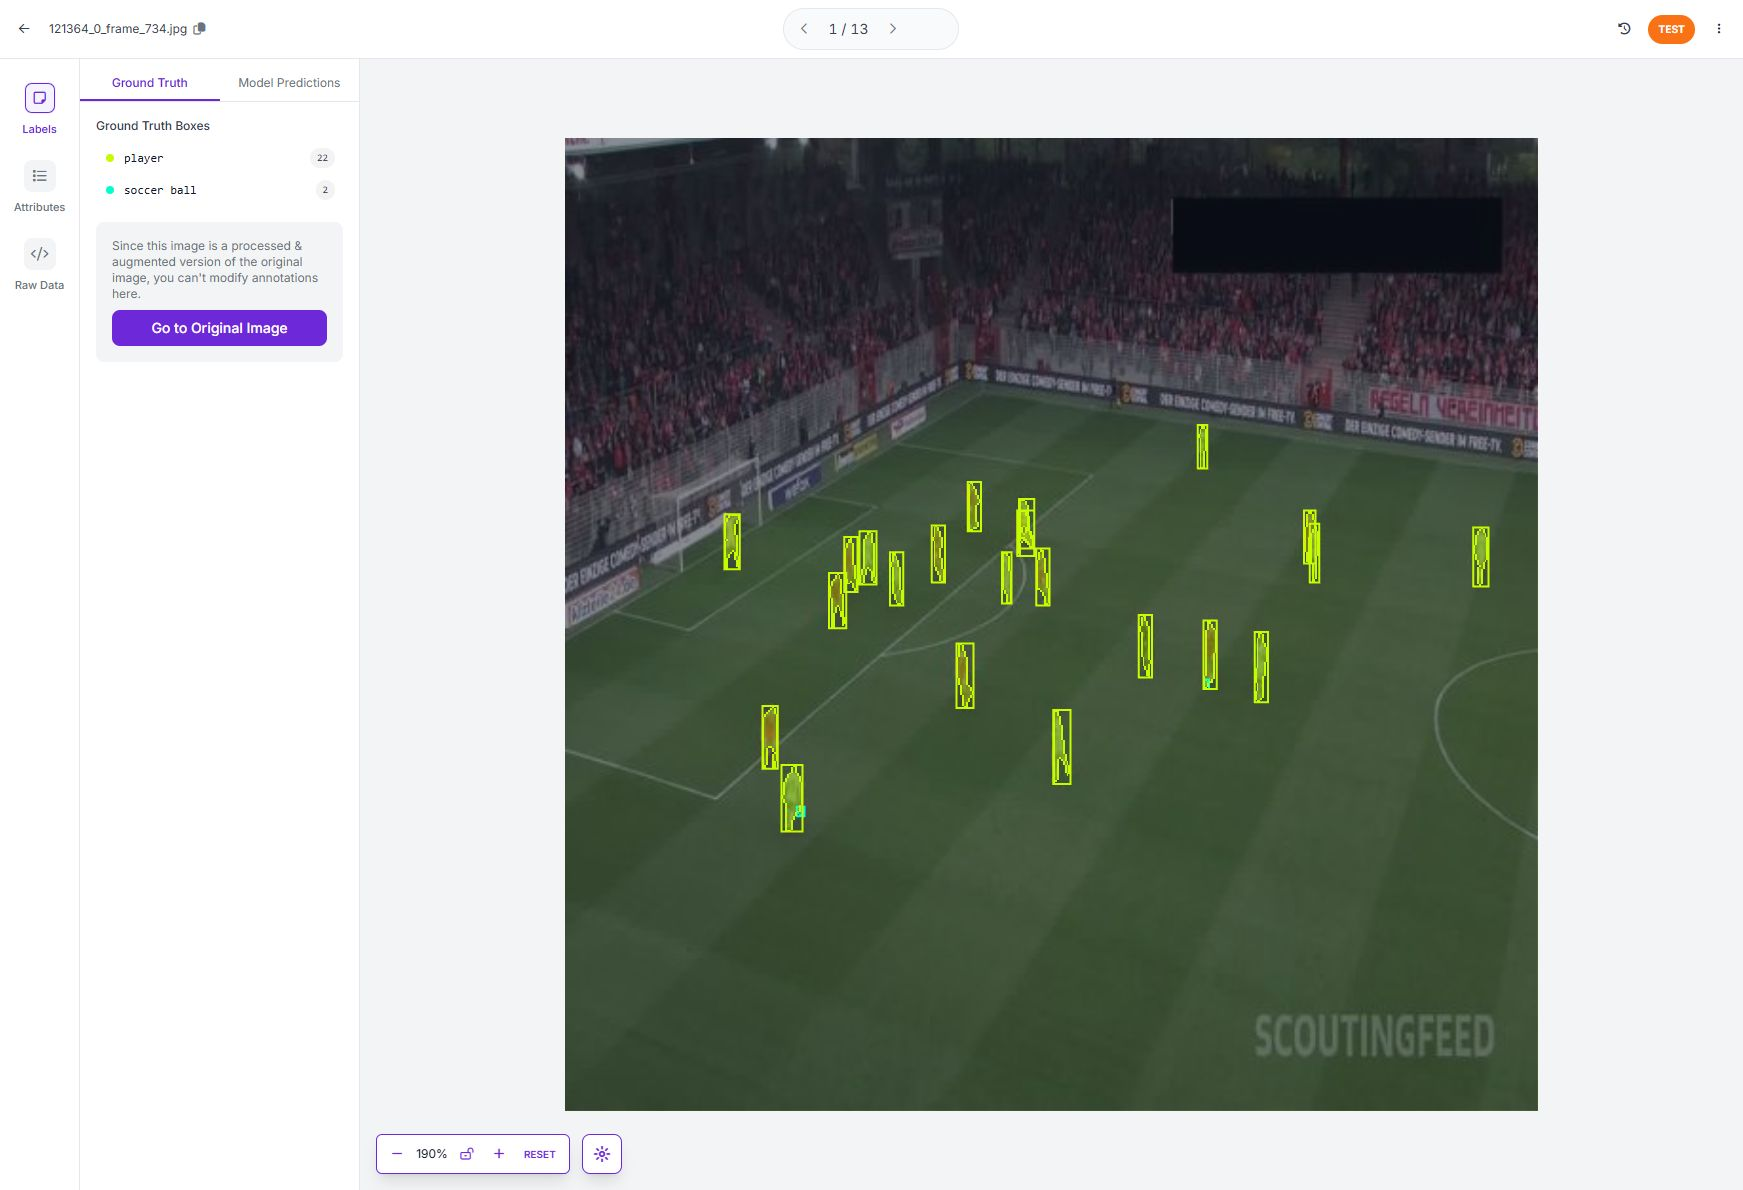

*Frame 734: stored ground-truth boxes; two soccer-ball labels are listed.*


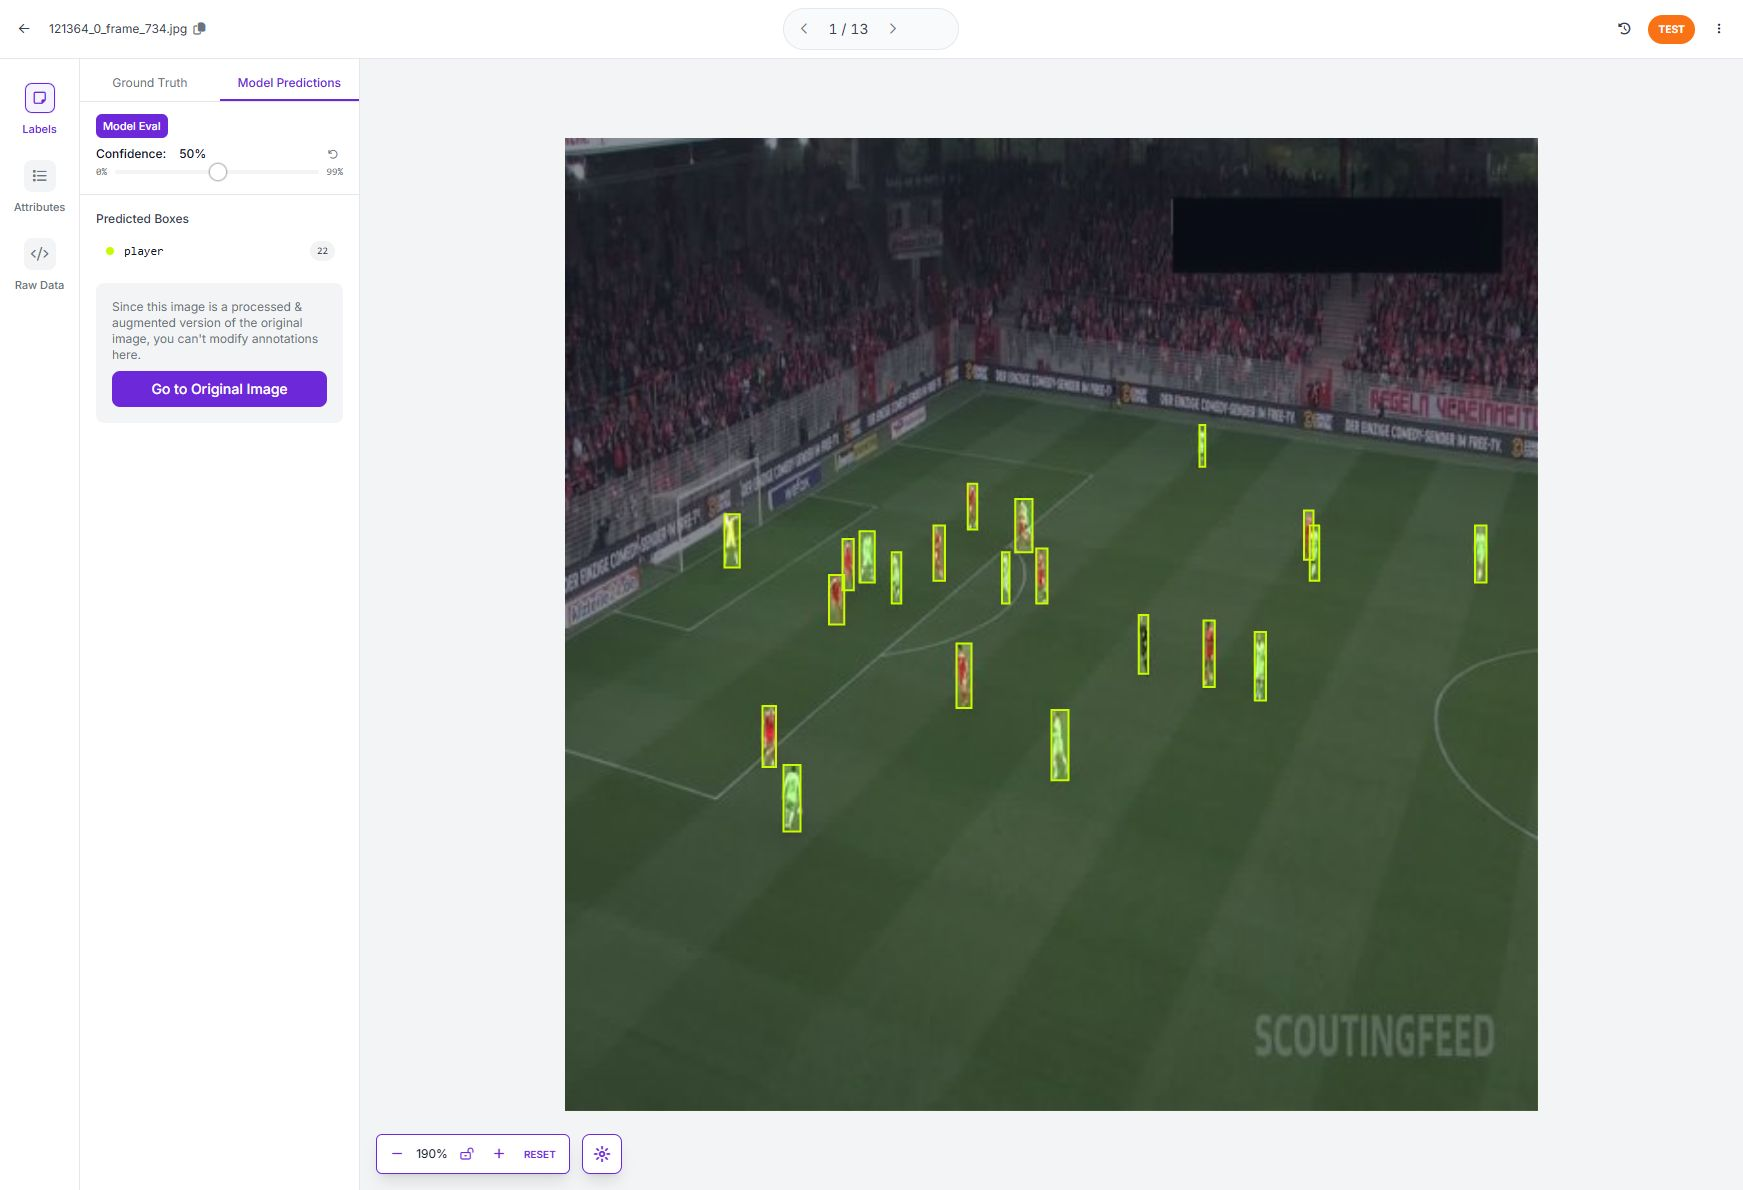

*Frame 734: model predictions at 50% confidence; no soccer ball is listed.*


### Frame 361

The stored ground truth lists 22 players and one soccer ball; the prediction view lists 23 players and no soccer ball at 50% confidence. Roboflow includes this image among the missed-ball examples. The small cyan ball box is close to a player near the center circle, making small size and proximity plausible difficulties. Confirm the object and bounding box in the original frame before attributing the miss to the model. The extra player prediction count alone does not identify which box is false.


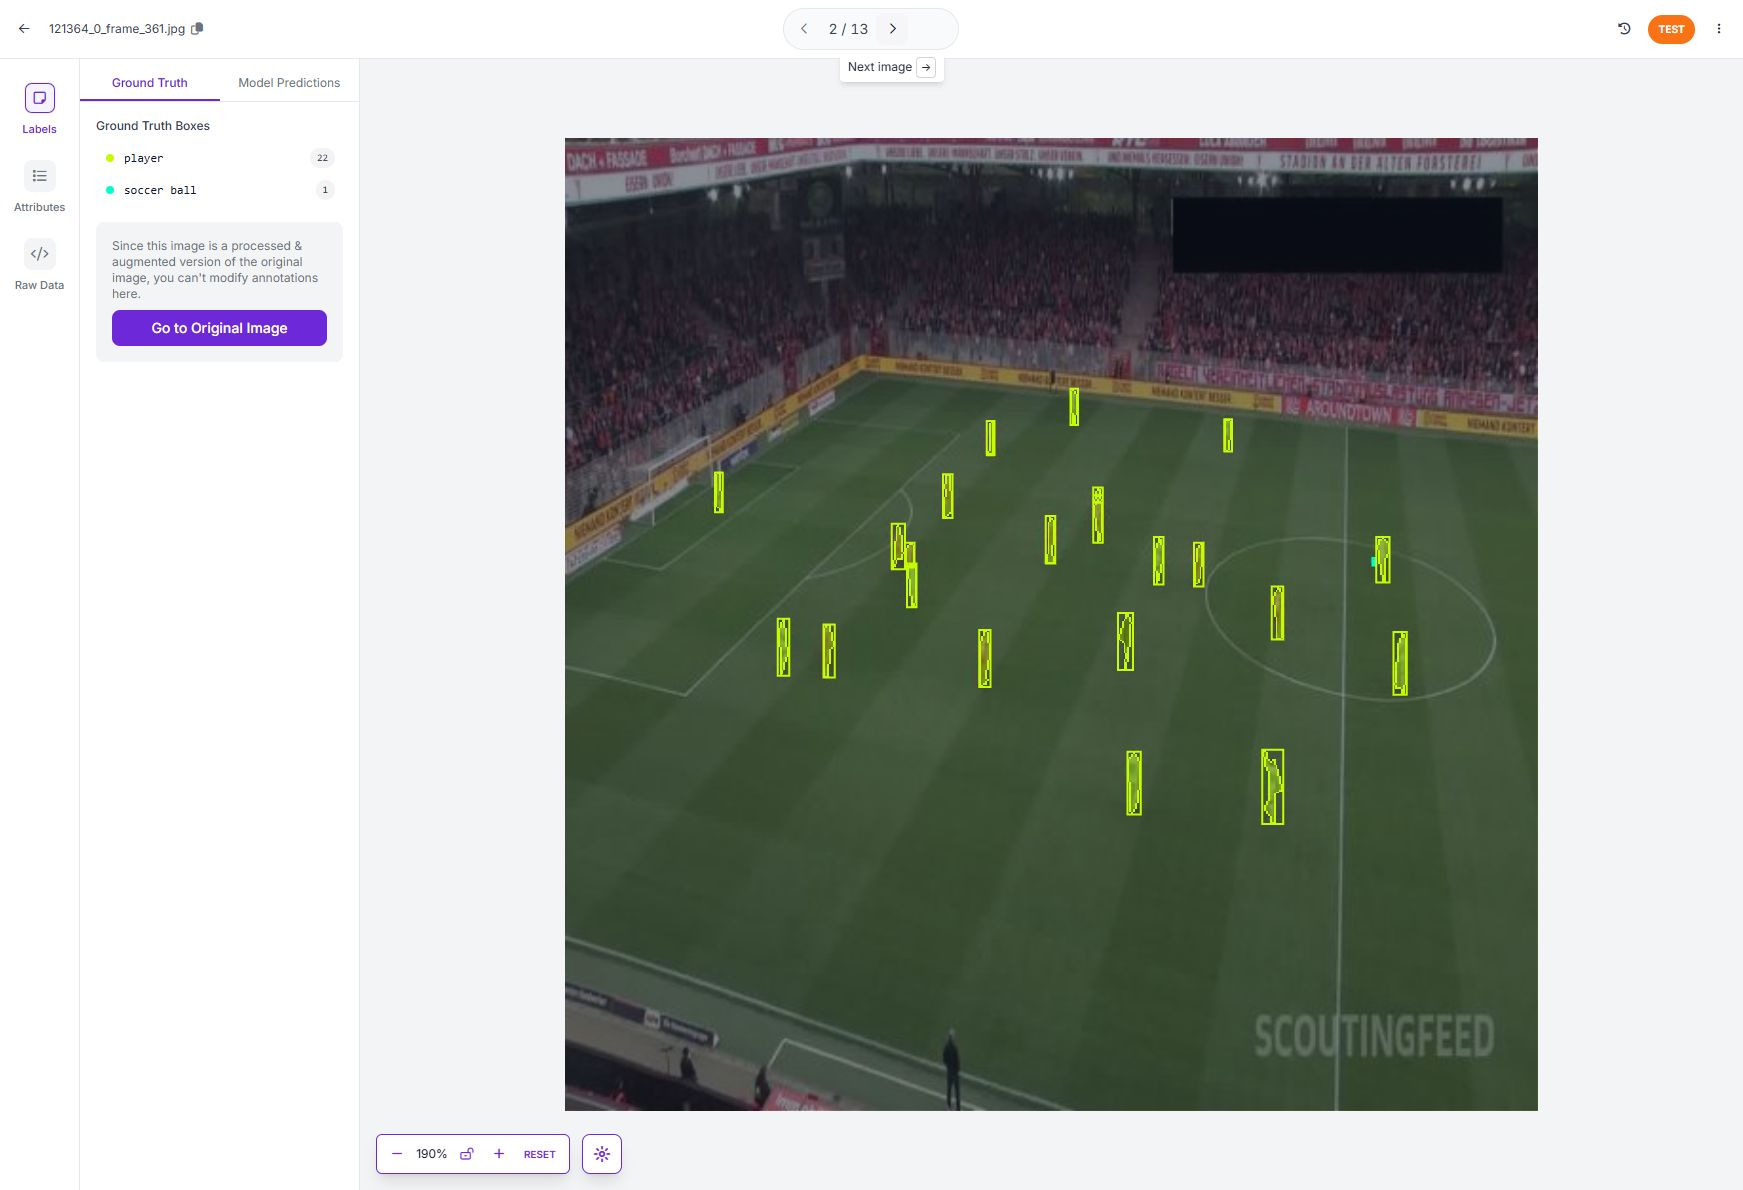

*Frame 361: stored ground truth, including one soccer-ball label.*


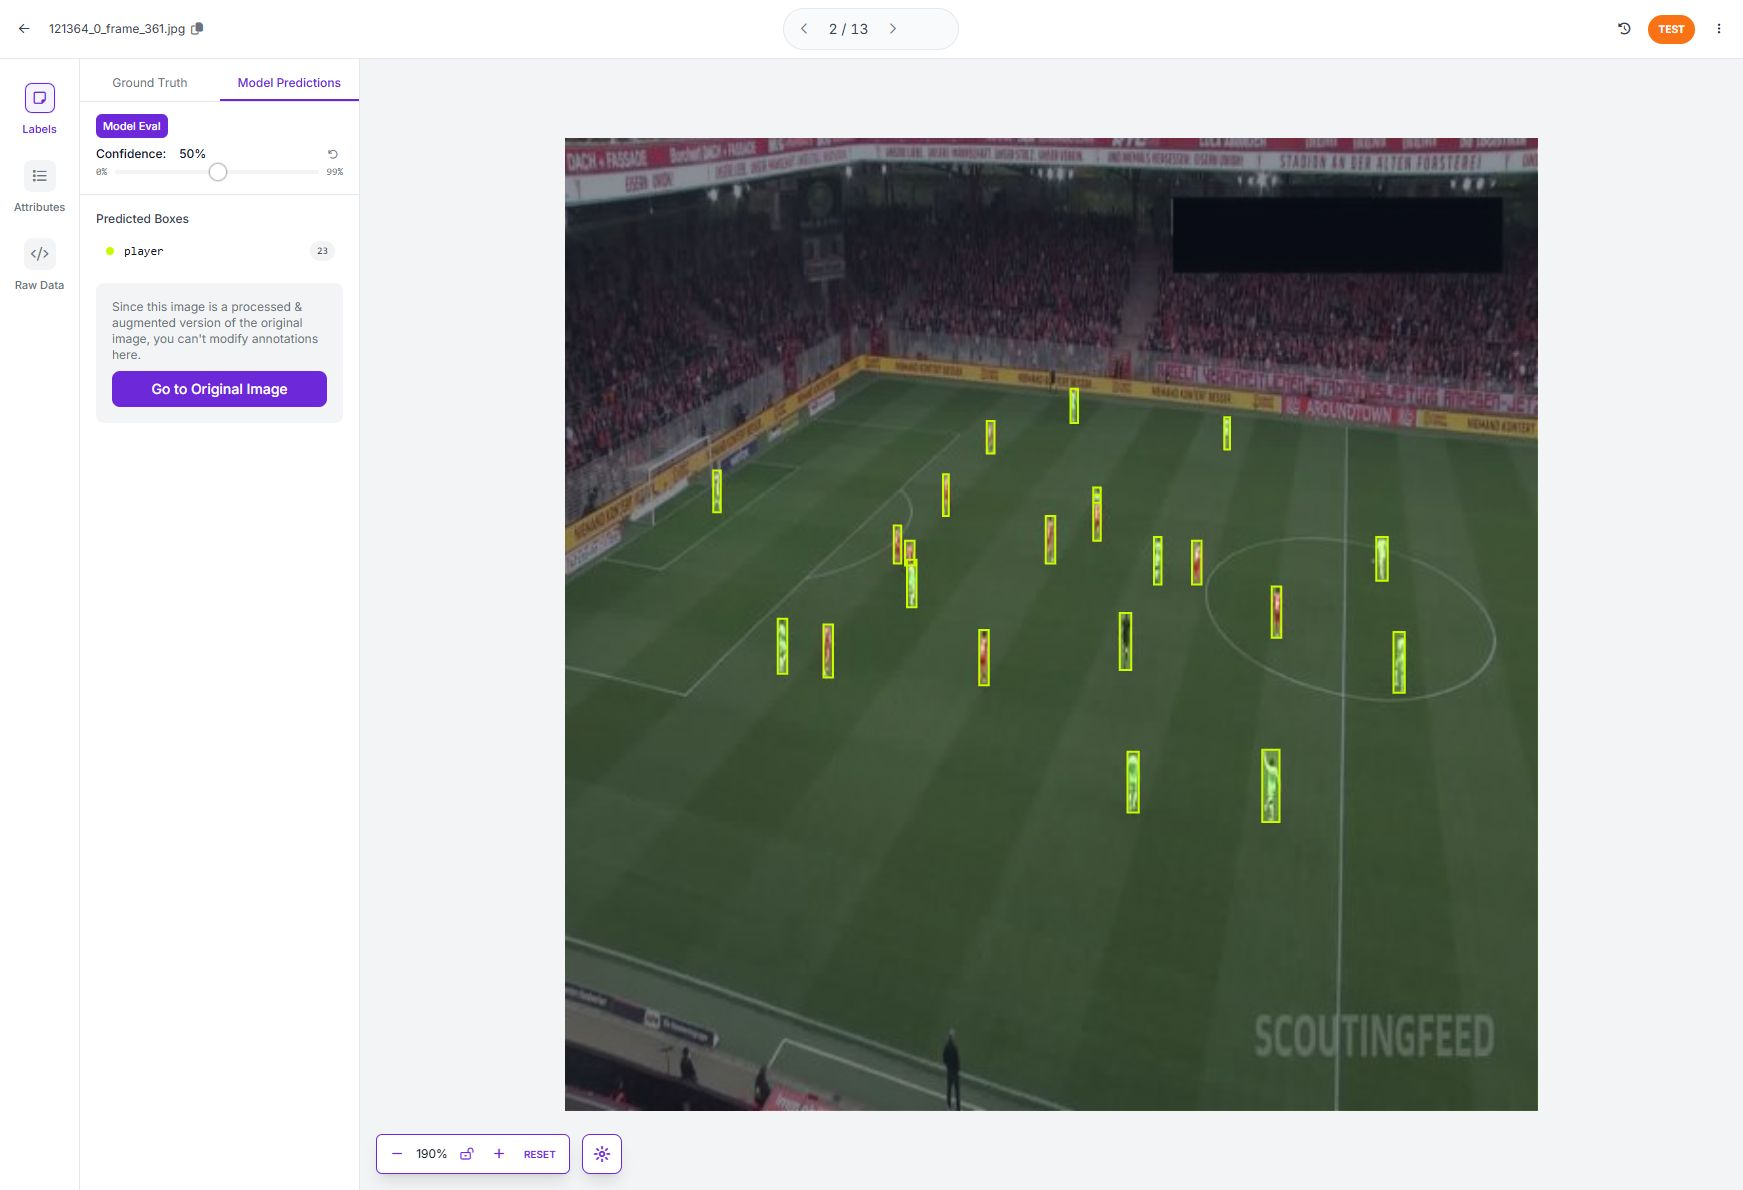

*Frame 361: model predictions at 50% confidence, with no soccer ball listed.*


**Review procedure:** compare the original frame and neighboring video frames, verify each ball’s identity and box, and check whether the model missed a valid label or the label needs correction. If a test label changes, regenerate or re-evaluate the dataset version and report the new metrics separately; do not silently replace the original results.

## Experiment history and interpretation

Roboflow lists version 1 (106 generated images, YOLO26 Small), version 2 (254, Small), version 4 (106, Large), and version 5 (1,255, Medium). These are generated-version counts, not necessarily independent source-frame counts. The team expanded the source dataset after an earlier test set contained only 11 images. Version 5 has 53 test images. The reasons for choosing Medium and the individual results of the earlier models have not been recorded, so no performance comparison or selection rationale is claimed. Color and blur augmentations were intended to expose the detector to varied conditions; their individual impact has not been measured.

The neighboring-frame split issue documented in the labeling notebook limits how confidently these test results can be generalized. A separate video or grouped time segment should be reserved for an independent evaluation.


## Follow-up checks


- Confirm the exported class names and IDs, including the empty `ball` class,
  and decide how they map to the intended downstream categories.
- Record the original frame count, selection method, split strategy, exact
  training settings, and evaluation procedure; confirm source split counts.
- Inspect representative false positives and missed balls and record their
  actual causes, including occlusion and blur where applicable.
- Evaluate on footage or time segments kept separate from training before
  relying on the detector for the tactical map.


## Verified project details

The [Roboflow model page](https://app.roboflow.com/liams-workspace-fkthi/football-players-and-ball-2gbhy/models/football-players-and-ball-2gbhy-5-yolo26m-t1) identifies version 5 and the Medium model. Its provider-reported validation mAP@50 is 87.0% overall, 97.0% for player and 77.0% for soccer ball. Roboflow notes that provider metrics may differ from its industry-standard evaluation, so they should not be directly compared with the test-set figures above. The detailed test-set evaluation reports mAP@50:95 of 31.4%.
